## EDA 노트북입니다

In [1]:
# 모듈 임포트 셀
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
plt.rcParams["font.family"] = "AppleGothic" # 한글 깨짐 방지
plt.rcParams["axes.unicode_minus"] = False
os.makedirs("../outputs", exist_ok=True)

In [3]:
# 데이터 불러오기
df = pd.read_csv("../data/clean.csv", encoding="utf-8-sig")
print(df.shape)
df["성장여부"].value_counts(normalize=True).round(3)

(13389, 57)


성장여부
0    0.673
1    0.327
Name: proportion, dtype: float64

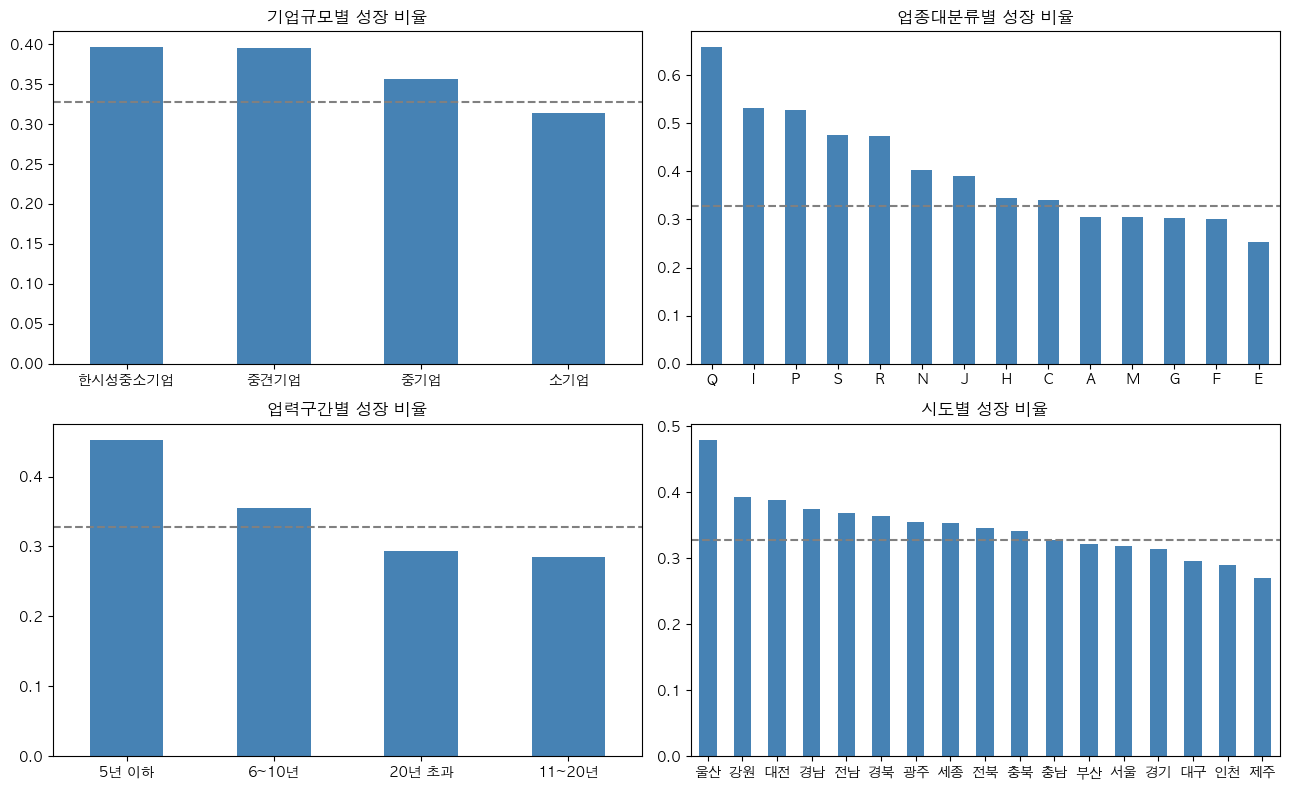

In [4]:
# 규모, 업종, 업력, 지역별 성장 비율
df["업력구간"] = pd.cut(df["업력"], bins=[-1, 5, 10, 20, 100], labels=["5년 이하", "6~10년", "11~20년", "20년 초과"])
groups = ["기업규모", "업종대분류", "업력구간", "시도"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i in range(4):
    ax = axes.flat[i]
    g = groups[i]
    cnt = df.groupby(g, observed=True).size()
    rate = df.groupby(g, observed=True)["성장여부"].mean()
    rate = rate[cnt >= 30].sort_values(ascending=False)   # 30개 미만 그룹은 제외
    rate.plot.bar(ax=ax, color="steelblue", rot=0)
    ax.axhline(df["성장여부"].mean(), color="gray", linestyle="--")   # 전체 평균
    ax.set_title(g + "별 성장 비율")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("../outputs/eda_growth_rate_by_group.png")
plt.show()

In [5]:
# 성장 여부별 주요 지표 중앙값
cols = ["업력", "24년 총자산", "24년 매출액", "24년 총자산회전율", "24년 부가가치율", "24년 차입금회전율", "24년 부채비율",
        "22년 총자산", "22년 총자산회전율", "22년 부가가치율", "22년 차입금회전율", "22년 부채비율",
        "자산성장률", "매출성장률"]
table = df.groupby("성장여부")[cols].median().T
table.columns = ["부", "여"]
table["차이"] = table["여"] - table["부"]
table.round(2)

,부,여,차이
업력,13.00,11.00,-2.00
24년 총자산,45.00,55.00,10.00
24년 매출액,35.10,30.60,-4.50
24년 총자산회전율,0.77,0.59,-0.18
24년 부가가치율,19.30,19.00,-0.30
24년 차입금회전율,3.24,4.36,1.12
24년 부채비율,1.21,1.57,0.36
22년 총자산,35.00,35.00,0.00
22년 총자산회전율,0.61,0.66,0.05
22년 부가가치율,17.20,19.80,2.60


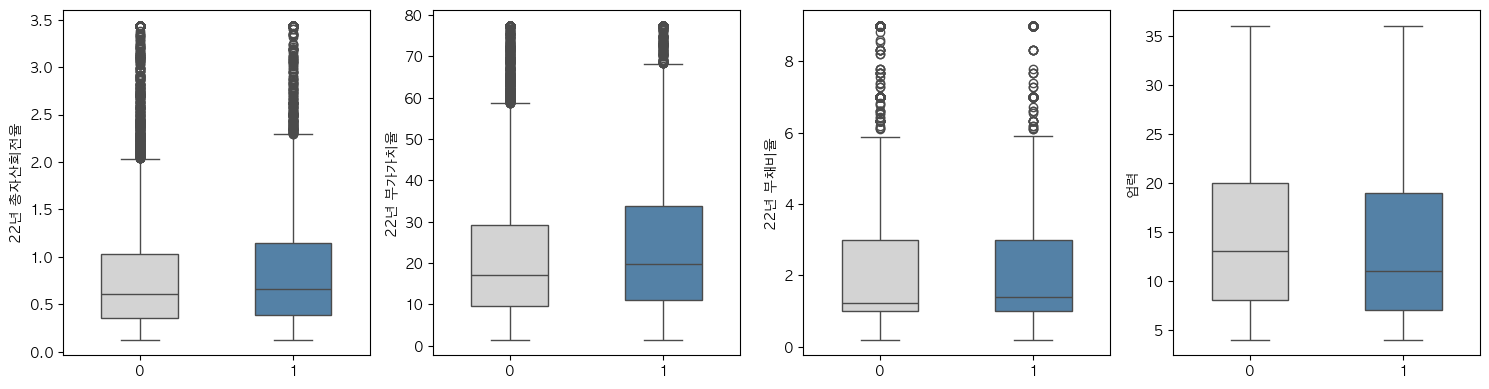

In [6]:
# 분포 비교 (상하위 2%는 잘라서 그림)
cols = ["22년 총자산회전율", "22년 부가가치율", "22년 부채비율", "업력"]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for i in range(4):
    col = cols[i]
    data = df[[col, "성장여부"]].dropna().copy()
    data[col] = data[col].clip(data[col].quantile(0.02), data[col].quantile(0.98))
    sns.boxplot(data=data, x="성장여부", y=col, hue="성장여부", palette=["lightgray", "steelblue"], width=0.5, legend=False, ax=axes[i])
    axes[i].set_xlabel("")
plt.tight_layout()
plt.savefig("../outputs/eda_boxplot.png")
plt.show()

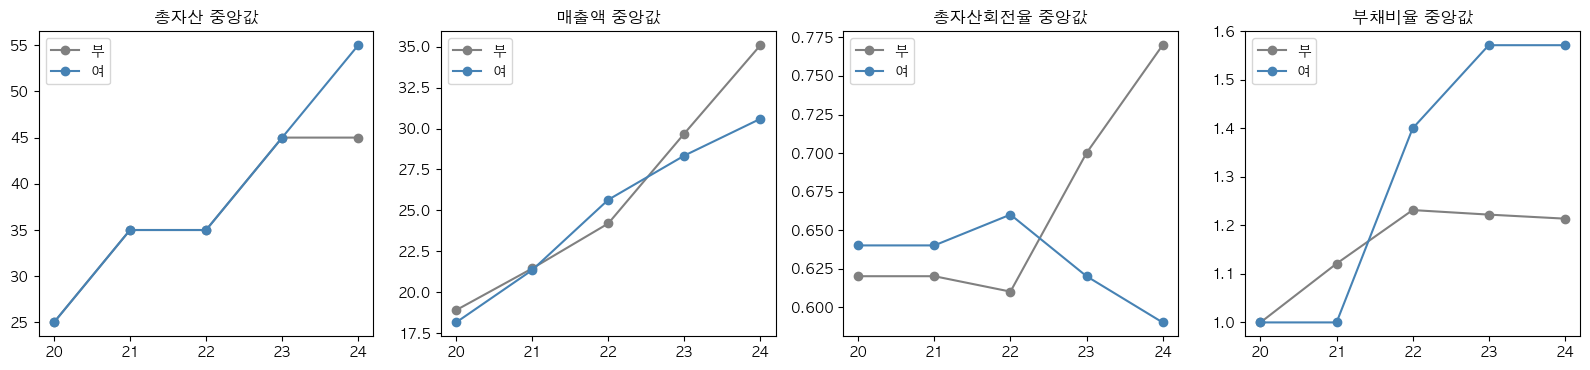

In [7]:
# 20년부터 24년까지 두 그룹의 중앙값 추세
years = ["20", "21", "22", "23", "24"]
items = ["총자산", "매출액", "총자산회전율", "부채비율"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for i in range(4):
    for label in [0, 1]:
        part = df[df["성장여부"] == label]
        values = []
        for y in years:
            values.append(part[y + "년 " + items[i]].median())
        color = "steelblue" if label == 1 else "gray"
        name = "여" if label == 1 else "부"
        axes[i].plot(years, values, marker="o", color=color, label=name)
    axes[i].set_title(items[i] + " 중앙값")
    axes[i].legend()
plt.tight_layout()
plt.savefig("../outputs/eda_trend.png")
plt.show()

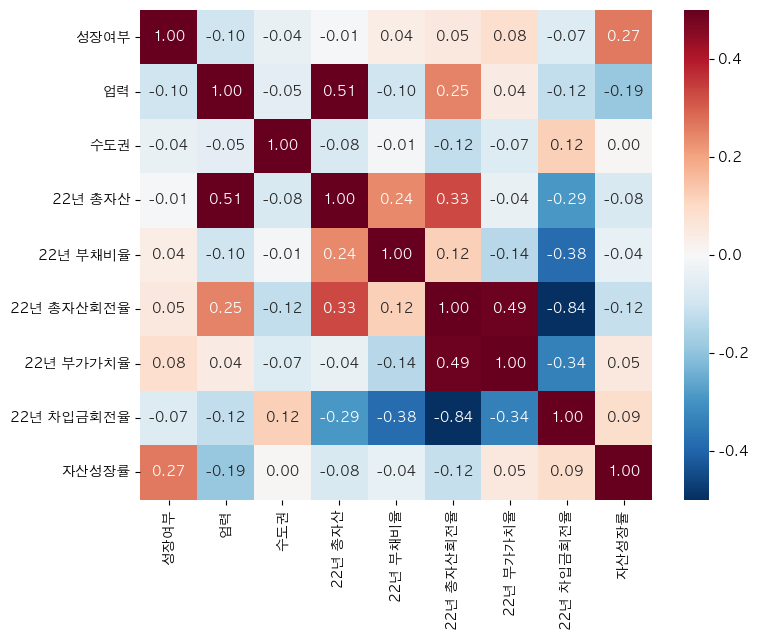

In [8]:
# 지표 간 상관관계 (22년 기준, 스피어만)
corr_cols = ["성장여부", "업력", "수도권", "22년 총자산", "22년 부채비율", "22년 총자산회전율",
             "22년 부가가치율", "22년 차입금회전율", "자산성장률"]
corr = df[corr_cols].corr(method="spearman")

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5)
plt.tight_layout()
plt.savefig("../outputs/eda_corr.png")
plt.show()

In [9]:
# 세부 업종별 성장 비율. 기업 수 100개 이상만
cnt = df["업종명"].value_counts()
big = cnt[cnt >= 100].index
sub = df[df["업종명"].isin(big)]
rate = sub.groupby("업종명")["성장여부"].agg(["mean", "size"]).sort_values("mean", ascending=False)
rate.round(3)

,mean,size
업종명,,
응용 소프트웨어 개발 및 공급업,0.497,155
그 외 자동차용 신품 부품 제조업,0.457,247
육류 포장육 및 냉동육 가공업 (가금류 제외),0.451,133
의약품 도매업,0.437,199
기타 가공식품 도매업,0.403,196
전자상거래 소매업,0.372,269
배관 및 냉ㆍ난방 공사업,0.345,119
"신선, 냉동 및 기타 수산물 도매업",0.331,160
"컴퓨터 및 주변장치, 소프트웨어 도매업",0.304,135


In [10]:
# 같은 업종 안에서 성장 여부별 지표 중앙값. 제조업(C), 도소매업(G)
cols = ["업력", "22년 총자산", "22년 총자산회전율", "22년 부가가치율", "22년 부채비율", "자산성장률"]
for code in ["C", "G"]:
    part = df[df["업종대분류"] == code]
    print(code, len(part))
    display(part.groupby("성장여부")[cols].median().round(2))

C 4992


,업력,22년 총자산,22년 총자산회전율,22년 부가가치율,22년 부채비율,자산성장률
성장여부,,,,,,
0,14.0,55.0,0.87,21.40,1.67,0.00
1,12.0,65.0,0.94,23.25,1.91,0.21


G 4935


,업력,22년 총자산,22년 총자산회전율,22년 부가가치율,22년 부채비율,자산성장률
성장여부,,,,,,
0,12.0,35.0,0.44,10.0,1.22,0.00
1,9.0,25.0,0.44,11.2,1.00,0.27


In [11]:
# 자본잠식, 상장 여부와 성장
print(df.groupby("22년 자본잠식")["성장여부"].agg(["mean", "size"]).round(3))
print()
print(df.groupby("상장등록법인")["성장여부"].agg(["mean", "size"]).round(3))

           mean   size
22년 자본잠식              
0         0.327  13197
1         0.370    192

          mean   size
상장등록법인               
W        0.385     65
기타       0.324  11752
등록법인     0.143     21
상장기업     0.316     19
외감법인     0.353   1466
코넥스상장기업  0.000      7
코스닥상장기업  0.390     59
